<a href="https://colab.research.google.com/github/etoo-blip/Machine-Learning-Homework-3/blob/main/Homework_3_Edwin_Too.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:

# Name: Edwin Too
# ID: 801549588
# HOMEWORK 3


# Import required libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import SGDClassifier

from sklearn.metrics import (
    log_loss,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

In [2]:

# PROBLEM 1: DIABETES CLASSIFICATION

# Load the diabetes dataset
diabetes = pd.read_csv("diabetes.csv")

# Display the first five rows
print("First five rows:")
display(diabetes.head())

# Display dataset information
print("\nDataset shape:", diabetes.shape)

print("\nMissing values:")
print(diabetes.isnull().sum())

print("\nOutcome counts:")
print(diabetes["Outcome"].value_counts())

First five rows:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1



Dataset shape: (768, 9)

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Outcome counts:
Outcome
0    500
1    268
Name: count, dtype: int64


In [3]:
# Separate the input features from the target variable
X_diabetes = diabetes.drop("Outcome", axis=1)
Y_diabetes = diabetes["Outcome"]

print("Number of input features:", X_diabetes.shape[1])
print("X shape:", X_diabetes.shape)
print("Y shape:", Y_diabetes.shape)

print("\nOutcome definition:")
print("0 = Negative for diabetes")
print("1 = Positive for diabetes")

Number of input features: 8
X shape: (768, 8)
Y shape: (768,)

Outcome definition:
0 = Negative for diabetes
1 = Positive for diabetes


In [4]:
# Split the dataset into 80% training and 20% testing
X_train_diabetes, X_test_diabetes, Y_train_diabetes, Y_test_diabetes = train_test_split(
    X_diabetes,
    Y_diabetes,
    test_size=0.20,
    random_state=100,
    stratify=Y_diabetes
)

print("X_train shape:", X_train_diabetes.shape)
print("X_test shape:", X_test_diabetes.shape)
print("Y_train shape:", Y_train_diabetes.shape)
print("Y_test shape:", Y_test_diabetes.shape)

print("\nTraining outcome counts:")
print(Y_train_diabetes.value_counts())

print("\nTest outcome counts:")
print(Y_test_diabetes.value_counts())

X_train shape: (614, 8)
X_test shape: (154, 8)
Y_train shape: (614,)
Y_test shape: (154,)

Training outcome counts:
Outcome
0    400
1    214
Name: count, dtype: int64

Test outcome counts:
Outcome
0    100
1     54
Name: count, dtype: int64


In [5]:
# Create a standard scaler
scaler_diabetes = StandardScaler()

# Fit the scaler using only the training data
X_train_diabetes_scaled = scaler_diabetes.fit_transform(
    X_train_diabetes
)

# Transform the test data using the same scaler
X_test_diabetes_scaled = scaler_diabetes.transform(
    X_test_diabetes
)

# Verify standardization
print("Mean of scaled training features:")
print(X_train_diabetes_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(X_train_diabetes_scaled.std(axis=0))

Mean of scaled training features:
[ 2.89308931e-17 -4.91825184e-17 -1.73585359e-17  6.65410542e-17
  8.31763178e-17 -2.86415842e-16  2.43019502e-16  1.56226823e-16]

Standard deviation of scaled training features:
[1. 1. 1. 1. 1. 1. 1. 1.]


In [6]:
# Create logistic regression classifier
# Weight penalty not used
diabetes_model = SGDClassifier(
    loss="log_loss",
    penalty=None,
    learning_rate="constant",
    eta0=0.01,
    random_state=100
)

# Number of training iterations
n_iterations_diabetes = 100

# Lists used to store training results
diabetes_train_losses = []
diabetes_train_accuracies = []

# Train one iteration at a time
for iteration in range(n_iterations_diabetes):

    diabetes_model.partial_fit(
        X_train_diabetes_scaled,
        Y_train_diabetes,
        classes=np.array([0, 1])
    )

    # Calculate training probabilities
    Y_train_diabetes_prob = diabetes_model.predict_proba(
        X_train_diabetes_scaled
    )

    # Calculate training predictions
    Y_train_diabetes_pred = diabetes_model.predict(
        X_train_diabetes_scaled
    )

    # Calculate log loss
    loss = log_loss(
        Y_train_diabetes,
        Y_train_diabetes_prob
    )

    # Calculate classification accuracy
    accuracy = accuracy_score(
        Y_train_diabetes,
        Y_train_diabetes_pred
    )

    diabetes_train_losses.append(loss)
    diabetes_train_accuracies.append(accuracy)

print("Final Training Loss:",
      diabetes_train_losses[-1])

print("Final Training Accuracy:",
      diabetes_train_accuracies[-1])

Final Training Loss: 0.4744006769135388
Final Training Accuracy: 0.7785016286644951


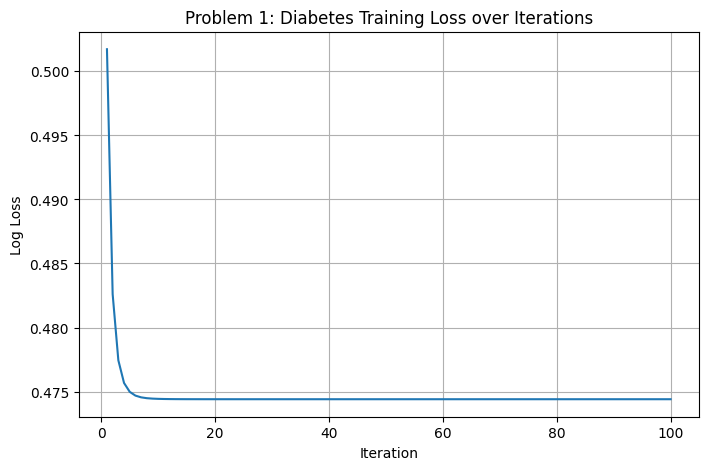

In [7]:
# Plot diabetes training loss
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_diabetes + 1),
    diabetes_train_losses
)

plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Problem 1: Diabetes Training Loss over Iterations")
plt.grid(True)

plt.show()

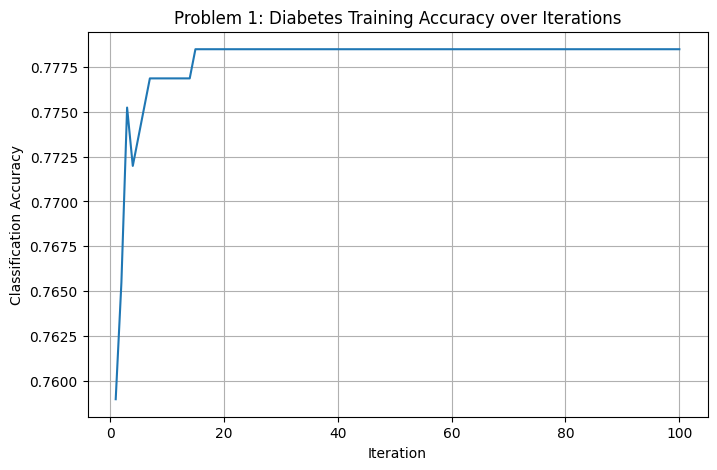

In [8]:
# Plot diabetes training accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_diabetes + 1),
    diabetes_train_accuracies
)

plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Problem 1: Diabetes Training Accuracy over Iterations")
plt.grid(True)

plt.show()

In [9]:
# Make predictions on the test data
Y_test_diabetes_pred = diabetes_model.predict(
    X_test_diabetes_scaled
)

# Calculate evaluation metrics
diabetes_accuracy = accuracy_score(
    Y_test_diabetes,
    Y_test_diabetes_pred
)

diabetes_precision = precision_score(
    Y_test_diabetes,
    Y_test_diabetes_pred
)

diabetes_recall = recall_score(
    Y_test_diabetes,
    Y_test_diabetes_pred
)

diabetes_f1 = f1_score(
    Y_test_diabetes,
    Y_test_diabetes_pred
)

print("Problem 1 Test Results")
print("----------------------")
print("Accuracy :", diabetes_accuracy)
print("Precision:", diabetes_precision)
print("Recall   :", diabetes_recall)
print("F1 Score :", diabetes_f1)

Problem 1 Test Results
----------------------
Accuracy : 0.7857142857142857
Precision: 0.7560975609756098
Recall   : 0.5740740740740741
F1 Score : 0.6526315789473685


Diabetes Confusion Matrix:
[[90 10]
 [23 31]]


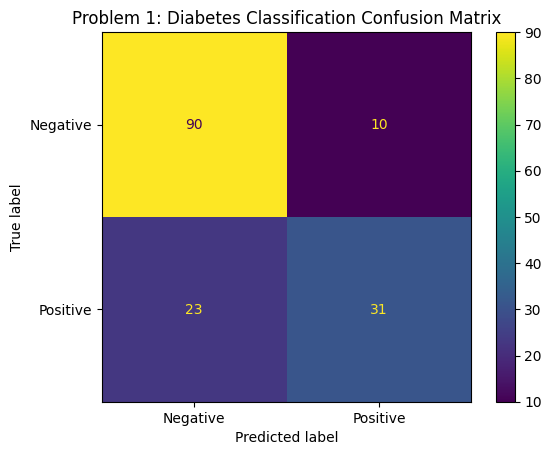

In [10]:
# Create confusion matrix
cm_diabetes = confusion_matrix(
    Y_test_diabetes,
    Y_test_diabetes_pred
)

print("Diabetes Confusion Matrix:")
print(cm_diabetes)

# Display confusion matrix
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_diabetes,
    display_labels=["Negative", "Positive"]
)

disp.plot()
plt.title("Problem 1: Diabetes Classification Confusion Matrix")
plt.show()

In [11]:

# PROBLEM 2: CANCER CLASSIFICATION

# Load the cancer dataset
cancer = pd.read_csv("Cancer.csv")

print("First five rows:")
display(cancer.head())

print("\nDataset shape:", cancer.shape)

print("\nDiagnosis counts:")
print(cancer["diagnosis"].value_counts())

print("\nColumns containing missing values:")
print(
    cancer.isnull().sum()[
        cancer.isnull().sum() > 0
    ]
)

First five rows:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN



Dataset shape: (569, 33)

Diagnosis counts:
diagnosis
B    357
M    212
Name: count, dtype: int64

Columns containing missing values:
Unnamed: 32    569
dtype: int64


In [12]:
# Remove columns that are not input measurements
X_cancer = cancer.drop(
    ["id", "diagnosis", "Unnamed: 32"],
    axis=1
)

# Convert diagnosis into binary values
# Malignant = 1
# Benign = 0
Y_cancer = cancer["diagnosis"].map({
    "M": 1,
    "B": 0
})

print("X shape:", X_cancer.shape)
print("Y shape:", Y_cancer.shape)

print("\nNumber of input features:",
      X_cancer.shape[1])

print("\nDiagnosis after conversion:")
print(Y_cancer.value_counts())

print("\nTotal missing values in the 30 input features:")
print(X_cancer.isnull().sum().sum())

X shape: (569, 30)
Y shape: (569,)

Number of input features: 30

Diagnosis after conversion:
diagnosis
0    357
1    212
Name: count, dtype: int64

Total missing values in the 30 input features:
0


In [13]:
# Split Cancer Dataset to 80% Training and 20% Testing
X_train_cancer, X_test_cancer, Y_train_cancer, Y_test_cancer = train_test_split(
    X_cancer,
    Y_cancer,
    test_size=0.20,
    random_state=100,
    stratify=Y_cancer
)

print("X_train shape:", X_train_cancer.shape)
print("X_test shape:", X_test_cancer.shape)
print("Y_train shape:", Y_train_cancer.shape)
print("Y_test shape:", Y_test_cancer.shape)

print("\nTraining diagnosis counts:")
print(Y_train_cancer.value_counts())

print("\nTest diagnosis counts:")
print(Y_test_cancer.value_counts())

X_train shape: (455, 30)
X_test shape: (114, 30)
Y_train shape: (455,)
Y_test shape: (114,)

Training diagnosis counts:
diagnosis
0    285
1    170
Name: count, dtype: int64

Test diagnosis counts:
diagnosis
0    72
1    42
Name: count, dtype: int64


In [14]:
# Standardize the cancer features

#Create standard scaler
scaler_cancer = StandardScaler()

# Fit using training data only
X_train_cancer_scaled = scaler_cancer.fit_transform(
    X_train_cancer
)

# Transform test data using the same scaler
X_test_cancer_scaled = scaler_cancer.transform(
    X_test_cancer
)

print("Mean of scaled training features:")
print(X_train_cancer_scaled.mean(axis=0))

print("\nStandard deviation of scaled training features:")
print(X_train_cancer_scaled.std(axis=0))

Mean of scaled training features:
[-2.45957101e-16  9.01842703e-16  6.28557035e-16 -7.80816193e-17
  9.56499837e-17  5.66091740e-17 -6.92974371e-17  1.75683643e-16
  3.78695854e-16 -4.89962161e-16  3.44047135e-17  7.80816193e-18
 -1.59091299e-16 -1.26882631e-16 -2.65477506e-16 -2.03012210e-16
 -1.63971401e-16  3.25990761e-16 -3.59175449e-16  6.05132550e-17
 -1.24930591e-16 -4.61657574e-16  6.24652955e-17 -6.63693764e-17
 -9.95540646e-17  3.12326477e-16  1.18098449e-16  2.10820372e-16
  4.29448906e-17  1.58115279e-16]

Standard deviation of scaled training features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.
 1. 1. 1. 1. 1. 1.]


In [15]:
# PROBLEM 2.1
# Logistic Regression without Weight Penalty
#

cancer_model = SGDClassifier(
    loss="log_loss",
    penalty=None,
    learning_rate="constant",
    eta0=0.01,
    random_state=100
)

n_iterations_cancer = 100

cancer_train_losses = []
cancer_train_accuracies = []

for iteration in range(n_iterations_cancer):

    cancer_model.partial_fit(
        X_train_cancer_scaled,
        Y_train_cancer,
        classes=np.array([0, 1])
    )

    # Training probabilities
    Y_train_cancer_prob = cancer_model.predict_proba(
        X_train_cancer_scaled
    )

    # Training predictions
    Y_train_cancer_pred = cancer_model.predict(
        X_train_cancer_scaled
    )

    # Calculate loss
    loss = log_loss(
        Y_train_cancer,
        Y_train_cancer_prob
    )

    # Calculate accuracy
    accuracy = accuracy_score(
        Y_train_cancer,
        Y_train_cancer_pred
    )

    cancer_train_losses.append(loss)
    cancer_train_accuracies.append(accuracy)

print("Final Training Loss:",
      cancer_train_losses[-1])

print("Final Training Accuracy:",
      cancer_train_accuracies[-1])

Final Training Loss: 0.051745019671423205
Final Training Accuracy: 0.9868131868131869


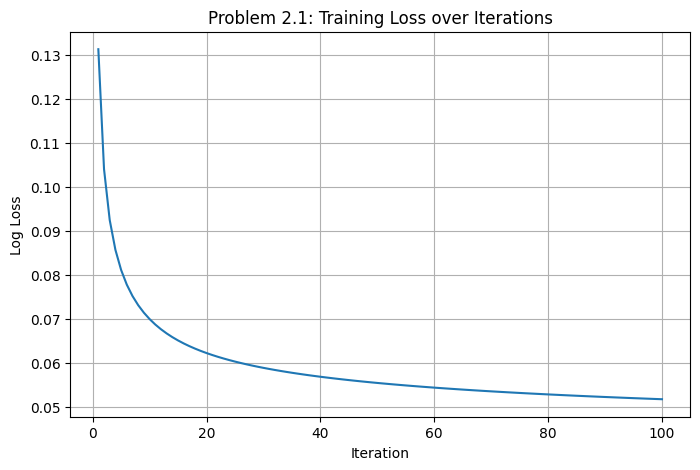

In [16]:
# Plot Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_cancer + 1),
    cancer_train_losses
)

plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Problem 2.1: Training Loss over Iterations")
plt.grid(True)

plt.show()

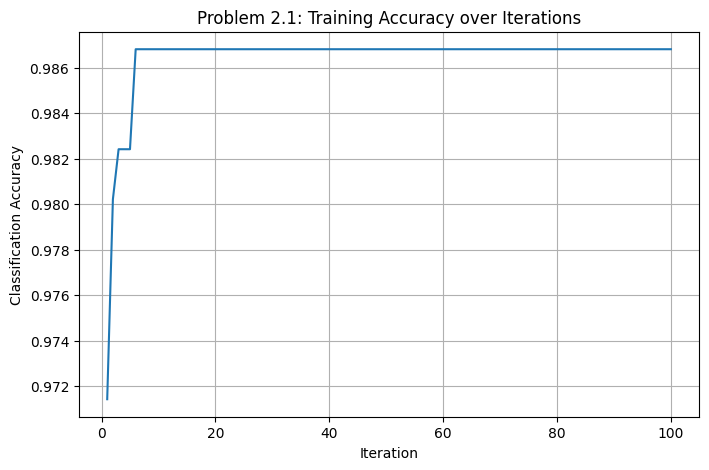

In [17]:
# Plot Training Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_cancer + 1),
    cancer_train_accuracies
)

plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Problem 2.1: Training Accuracy over Iterations")
plt.grid(True)

plt.show()

In [18]:
# Predict the test data
Y_test_cancer_pred = cancer_model.predict(
    X_test_cancer_scaled
)

# Calculate metrics
cancer_test_accuracy = accuracy_score(
    Y_test_cancer,
    Y_test_cancer_pred
)

cancer_test_precision = precision_score(
    Y_test_cancer,
    Y_test_cancer_pred
)

cancer_test_recall = recall_score(
    Y_test_cancer,
    Y_test_cancer_pred
)

cancer_test_f1 = f1_score(
    Y_test_cancer,
    Y_test_cancer_pred
)

print("Problem 2.1 Test Results")
print("------------------------")
print("Accuracy :", cancer_test_accuracy)
print("Precision:", cancer_test_precision)
print("Recall   :", cancer_test_recall)
print("F1 Score :", cancer_test_f1)

Problem 2.1 Test Results
------------------------
Accuracy : 0.9649122807017544
Precision: 0.9318181818181818
Recall   : 0.9761904761904762
F1 Score : 0.9534883720930233


Problem 2.1 Confusion Matrix:
[[69  3]
 [ 1 41]]


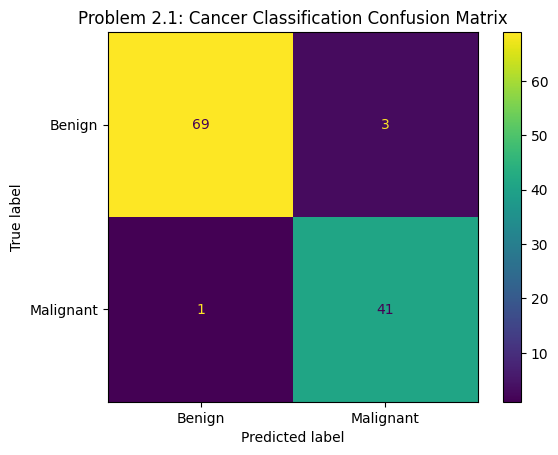

In [19]:
#confusion matrix
cm_cancer = confusion_matrix(
    Y_test_cancer,
    Y_test_cancer_pred
)

print("Problem 2.1 Confusion Matrix:")
print(cm_cancer)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cancer,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Problem 2.1: Cancer Classification Confusion Matrix")
plt.show()

In [20]:

# PROBLEM 2.2
# Logistic Regression WITH L2 Penalty


cancer_model_l2 = SGDClassifier(
    loss="log_loss",
    penalty="l2",
    alpha=0.0001,
    learning_rate="constant",
    eta0=0.01,
    random_state=100
)

n_iterations_cancer_l2 = 100

cancer_l2_losses = []
cancer_l2_accuracies = []

for iteration in range(n_iterations_cancer_l2):

    cancer_model_l2.partial_fit(
        X_train_cancer_scaled,
        Y_train_cancer,
        classes=np.array([0, 1])
    )

    # Training probabilities
    Y_train_cancer_prob_l2 = cancer_model_l2.predict_proba(
        X_train_cancer_scaled
    )

    # Training predictions
    Y_train_cancer_pred_l2 = cancer_model_l2.predict(
        X_train_cancer_scaled
    )

    # Classification log loss
    loss = log_loss(
        Y_train_cancer,
        Y_train_cancer_prob_l2
    )

    # Training accuracy
    accuracy = accuracy_score(
        Y_train_cancer,
        Y_train_cancer_pred_l2
    )

    cancer_l2_losses.append(loss)
    cancer_l2_accuracies.append(accuracy)

print("Final L2 Training Loss:",
      cancer_l2_losses[-1])

print("Final L2 Training Accuracy:",
      cancer_l2_accuracies[-1])

Final L2 Training Loss: 0.05198315020491392
Final L2 Training Accuracy: 0.9868131868131869


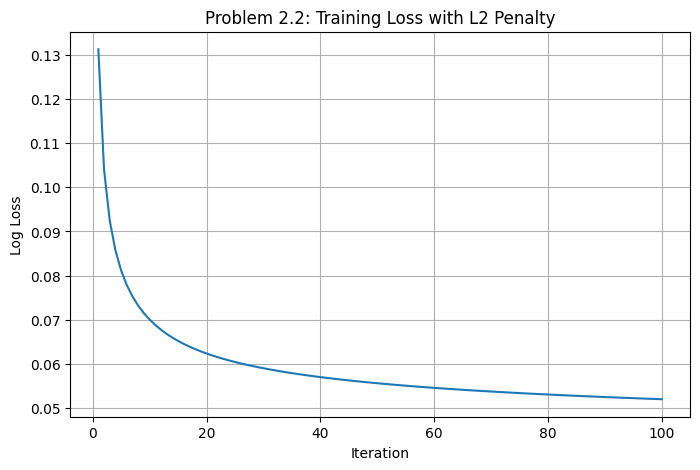

In [21]:
# Plot L2 Training Loss
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_cancer_l2 + 1),
    cancer_l2_losses
)

plt.xlabel("Iteration")
plt.ylabel("Log Loss")
plt.title("Problem 2.2: Training Loss with L2 Penalty")
plt.grid(True)

plt.show()

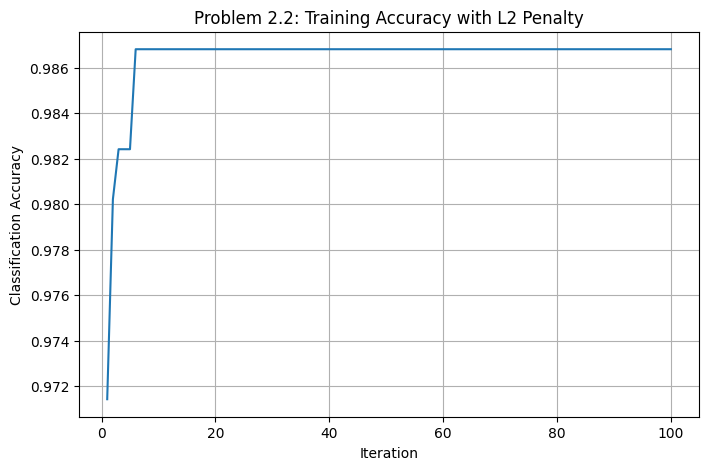

In [22]:
#Plot L2 Training Accuracy
plt.figure(figsize=(8, 5))

plt.plot(
    range(1, n_iterations_cancer_l2 + 1),
    cancer_l2_accuracies
)

plt.xlabel("Iteration")
plt.ylabel("Classification Accuracy")
plt.title("Problem 2.2: Training Accuracy with L2 Penalty")
plt.grid(True)

plt.show()

In [23]:
# Predict test data using L2 model
Y_test_cancer_pred_l2 = cancer_model_l2.predict(
    X_test_cancer_scaled
)

# Calculate evaluation metrics
cancer_l2_accuracy = accuracy_score(
    Y_test_cancer,
    Y_test_cancer_pred_l2
)

cancer_l2_precision = precision_score(
    Y_test_cancer,
    Y_test_cancer_pred_l2
)

cancer_l2_recall = recall_score(
    Y_test_cancer,
    Y_test_cancer_pred_l2
)

cancer_l2_f1 = f1_score(
    Y_test_cancer,
    Y_test_cancer_pred_l2
)

print("Problem 2.2 Test Results")
print("------------------------")
print("Accuracy :", cancer_l2_accuracy)
print("Precision:", cancer_l2_precision)
print("Recall   :", cancer_l2_recall)
print("F1 Score :", cancer_l2_f1)

Problem 2.2 Test Results
------------------------
Accuracy : 0.9649122807017544
Precision: 0.9318181818181818
Recall   : 0.9761904761904762
F1 Score : 0.9534883720930233


Problem 2.2 Confusion Matrix:
[[69  3]
 [ 1 41]]


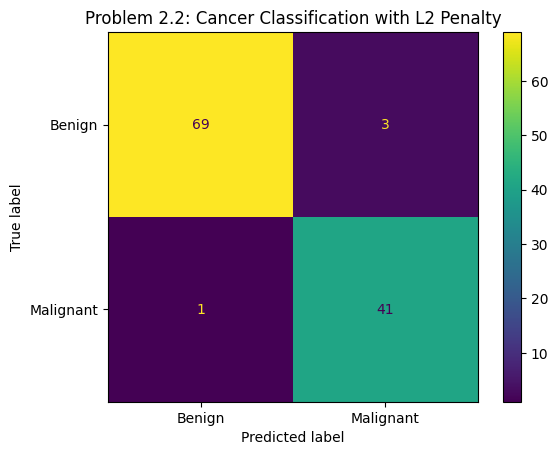

In [24]:
cm_cancer_l2 = confusion_matrix(
    Y_test_cancer,
    Y_test_cancer_pred_l2
)

print("Problem 2.2 Confusion Matrix:")
print(cm_cancer_l2)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_cancer_l2,
    display_labels=["Benign", "Malignant"]
)

disp.plot()
plt.title("Problem 2.2: Cancer Classification with L2 Penalty")
plt.show()

In [25]:

# Proplem 2.1 and Problem 2.2 comparison


comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression - No Penalty",
        "Logistic Regression - L2 Penalty"
    ],

    "Accuracy": [
        cancer_test_accuracy,
        cancer_l2_accuracy
    ],

    "Precision": [
        cancer_test_precision,
        cancer_l2_precision
    ],

    "Recall": [
        cancer_test_recall,
        cancer_l2_recall
    ],

    "F1 Score": [
        cancer_test_f1,
        cancer_l2_f1
    ]
})

comparison

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression - No Penalty,0.964912,0.931818,0.97619,0.953488
1,Logistic Regression - L2 Penalty,0.964912,0.931818,0.97619,0.953488
